# Baseline Model Evaluation

## Project Overview

This notebook documents the baseline forecasting evaluation for the AI Quantitative Trading & Decision Intelligence System.

The pilot asset is Lloyds Banking Group (LLOY.L), listed on the London Stock Exchange. The analysis uses historical market data and a chronological development, validation and test design.

The purpose is to establish transparent reference points before evaluating more complex forecasting models.

**Scope:** analyse existing baseline evaluation results only. This notebook does not train models, conduct backtests or initiate paper trading.

## 1. Evaluation Methodology

The forecasting target is the execution-price return:

\[
R(t,h) = \frac{Close(t+h)}{Open(t+1)} - 1
\]

where the forecast is generated after the close of session \(t\), the entry reference is the next session's opening price, and the exit reference is the closing price at horizon \(h\).

The evaluation horizons are 1, 5 and 10 trading sessions.

The temporal design is:

- **Development:** 24 October 2016 – 20 October 2023.
- **Validation:** 23 October 2023 – 22 October 2025.
- **Final test:** 23 October 2025 – 23 October 2026.

The final test period must remain isolated from model selection and strategy development. Baseline performance discussed in this notebook is based on the validation period.

## 2. Baseline Models

Three reference forecasting approaches are evaluated:

1. **Zero Return:** predicts a return of zero.
2. **Historical Mean:** predicts the mean of eligible historical training targets.
3. **Historical Median:** predicts the median of eligible historical training targets.

The baseline evaluation uses weekly retraining. Historical targets must be eligible at the relevant prediction time, avoiding the use of outcomes that have not yet matured.

These baselines establish reference performance; they are not evidence of a profitable trading strategy.

## 3. Evaluation Metrics

The primary metrics are:

- **Mean Absolute Error (MAE):** average absolute prediction error.
- **Root Mean Squared Error (RMSE):** square root of average squared prediction error.

Complementary metrics are:

- **Directional Accuracy:** proportion of predictions whose direction matches the realised return.
- **Spearman Correlation:** rank correlation between predictions and realised returns.
- **R-squared:** predictive performance relative to the validation sample mean.

Returns and MAE/RMSE are expressed in decimal return units. For example, a return of 0.01 corresponds to 1%.

A constant zero-return prediction has no variation, so its Spearman correlation is undefined. Negative R-squared values indicate that the predictions perform worse under this metric than predicting the observed validation-sample mean.

In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Load existing results without retraining or changing the evaluation.
# Resolve the results directory from common notebook working directories.
candidates = [
    Path("reports/baseline_evaluation"),
    Path("../reports/baseline_evaluation"),
]
results_dir = next(
    (candidate for candidate in candidates if (candidate / "baseline_metrics.csv").is_file()),
    None,
)
if results_dir is None:
    raise FileNotFoundError("Could not locate reports/baseline_evaluation.")

metrics = pd.read_csv(results_dir / "baseline_metrics.csv")
paired_tests = pd.read_csv(
    results_dir / "baseline_paired_statistical_tests.csv"
)
bootstrap = pd.read_csv(
    results_dir / "baseline_bootstrap_robustness.csv"
)

print("Baseline metrics:", metrics.shape)
print("Paired statistical tests:", paired_tests.shape)
print("Bootstrap robustness results:", bootstrap.shape)

display(metrics)

Baseline metrics: (9, 8)
Paired statistical tests: (18, 15)
Bootstrap robustness results: (54, 10)


,horizon,model,sample_size,mae,rmse,directional_accuracy,spearman_correlation,r_squared
0,1,historical_mean,507,0.009777,0.013672,0.499014,-0.094001,-0.006982
1,1,historical_median,507,0.009812,0.013706,0.469428,-0.090335,-0.012020
2,1,zero_return,507,0.009775,0.013668,0.469428,NaN,-0.006446
3,5,historical_mean,507,0.026529,0.035942,0.587771,-0.112736,-0.041122
4,5,historical_median,507,0.026800,0.036161,0.441815,-0.104527,-0.053846
5,5,zero_return,507,0.026672,0.036054,0.382643,NaN,-0.047619
6,10,historical_mean,507,0.039749,0.051877,0.631164,-0.134977,-0.087566
7,10,historical_median,507,0.040274,0.052362,0.485207,-0.110397,-0.107960
8,10,zero_return,507,0.040146,0.052276,0.343195,NaN,-0.104330


## 4. Predictive Performance

The following table summarises the existing validation metrics by forecasting horizon and baseline model.

Interpret MAE and RMSE alongside the complementary metrics. No single metric establishes that a model can generate positive net trading returns.

,horizon,model,sample_size,mae,rmse,directional_accuracy,spearman_correlation,r_squared
0,1,zero_return,507,0.009775,0.013668,0.469428,NaN,-0.006446
1,1,historical_mean,507,0.009777,0.013672,0.499014,-0.094001,-0.006982
2,1,historical_median,507,0.009812,0.013706,0.469428,-0.090335,-0.012020
3,5,historical_mean,507,0.026529,0.035942,0.587771,-0.112736,-0.041122
4,5,zero_return,507,0.026672,0.036054,0.382643,NaN,-0.047619
5,5,historical_median,507,0.026800,0.036161,0.441815,-0.104527,-0.053846
6,10,historical_mean,507,0.039749,0.051877,0.631164,-0.134977,-0.087566
7,10,zero_return,507,0.040146,0.052276,0.343195,NaN,-0.104330
8,10,historical_median,507,0.040274,0.052362,0.485207,-0.110397,-0.107960


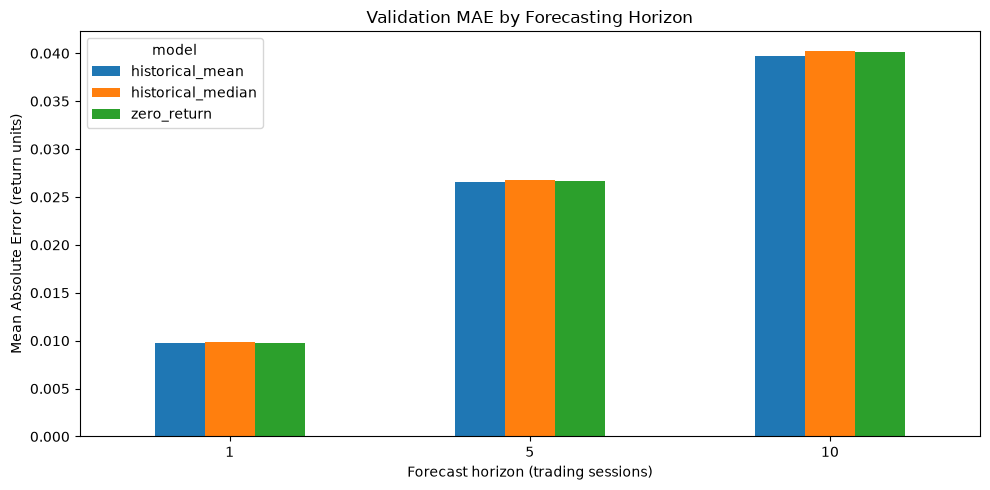

In [4]:
# Compare the primary validation metrics across horizons and models.
display(
    metrics.sort_values(["horizon", "mae"])[
        [
            "horizon",
            "model",
            "sample_size",
            "mae",
            "rmse",
            "directional_accuracy",
            "spearman_correlation",
            "r_squared",
        ]
    ].reset_index(drop=True)
)

# Plot MAE by horizon using the existing evaluation results.
mae_pivot = metrics.pivot(
    index="horizon", columns="model", values="mae"
)
ax = mae_pivot.plot(kind="bar", figsize=(10, 5))
ax.set_title("Validation MAE by Forecasting Horizon")
ax.set_xlabel("Forecast horizon (trading sessions)")
ax.set_ylabel("Mean Absolute Error (return units)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Statistical Comparison

Paired statistical comparisons assess differences in prediction loss on common validation observations.

The existing analysis includes:

- Absolute and squared prediction loss.
- HAC/Newey–West inference to account for serial dependence and heteroskedasticity.
- Circular block-bootstrap confidence intervals.
- Holm correction across the 18 confirmatory comparisons.

The significance level is 0.05. Corrected p-values, confidence intervals and the definition of each comparison should be considered together.

Bootstrap confidence intervals are complementary robustness evidence; they do not replace the pre-specified HAC tests and multiple-comparison correction.

In [5]:
# Inspect the recorded statistical comparisons and their column definitions.
print("Paired-test columns:")
print(paired_tests.columns.tolist())

display(paired_tests)

# Show comparisons with a Holm-adjusted p-value below 0.05, if available.
holm_columns = [
    column for column in paired_tests.columns
    if "holm" in column.lower() and "p" in column.lower()
]

if holm_columns:
    adjusted_p = holm_columns[0]
    print(f"Comparisons with {adjusted_p} < 0.05:")
    display(paired_tests.loc[paired_tests[adjusted_p] < 0.05])
else:
    print(
        "No Holm-adjusted p-value column was identified automatically. "
        "Inspect the table above and its column names."
    )

Paired-test columns:
['horizon', 'loss', 'model_a', 'model_b', 'sample_size', 'mean_loss_difference_a_minus_b', 'hac_lag', 'hac_standard_error', 'hac_z_statistic', 'hac_p_value', 'block_length', 'bootstrap_ci_95_lower', 'bootstrap_ci_95_upper', 'holm_adjusted_p_value', 'significant_after_holm_5pct']


,horizon,loss,model_a,model_b,sample_size,mean_loss_difference_a_minus_b,hac_lag,hac_standard_error,hac_z_statistic,hac_p_value,block_length,bootstrap_ci_95_lower,bootstrap_ci_95_upper,holm_adjusted_p_value,significant_after_holm_5pct
0,1,absolute,historical_mean,historical_median,507,-3.480559e-05,10,1.792193e-05,-1.942067,0.052129,10,-7.070268e-05,-9.581074e-07,0.364903,False
1,1,squared,historical_mean,historical_median,507,-9.352043e-07,10,4.372799e-07,-2.138686,0.032461,10,-1.790468e-06,-9.401055e-08,0.292150,False
2,1,absolute,historical_mean,zero_return,507,1.681829e-06,10,4.275511e-06,0.393363,0.694051,10,-6.685672e-06,9.994297e-06,1.000000,False
3,1,squared,historical_mean,zero_return,507,9.936767e-08,10,1.155762e-07,0.859759,0.389922,10,-1.226599e-07,3.257264e-07,1.000000,False
4,1,absolute,historical_median,zero_return,507,3.648742e-05,10,1.668655e-05,2.186637,0.028769,10,4.633963e-06,6.929992e-05,0.288611,False
5,1,squared,historical_median,zero_return,507,1.034572e-06,10,4.195636e-07,2.465829,0.013670,10,2.571584e-07,1.872189e-06,0.202258,False
6,5,absolute,historical_mean,historical_median,507,-2.707928e-04,10,8.073356e-05,-3.354154,0.000796,10,-4.233314e-04,-1.068518e-04,0.014329,True
7,5,squared,historical_mean,historical_median,507,-1.578803e-05,10,6.390033e-06,-2.470728,0.013484,10,-2.756702e-05,-3.310939e-06,0.202258,False
8,5,absolute,historical_mean,zero_return,507,-1.429922e-04,10,6.317129e-05,-2.263563,0.023601,10,-2.659711e-04,-1.998253e-05,0.283212,False
9,5,squared,historical_mean,zero_return,507,-8.060375e-06,10,5.020221e-06,-1.605582,0.108366,10,-1.799745e-05,2.099496e-06,0.623988,False


Comparisons with holm_adjusted_p_value < 0.05:


,horizon,loss,model_a,model_b,sample_size,mean_loss_difference_a_minus_b,hac_lag,hac_standard_error,hac_z_statistic,hac_p_value,block_length,bootstrap_ci_95_lower,bootstrap_ci_95_upper,holm_adjusted_p_value,significant_after_holm_5pct
6,5,absolute,historical_mean,historical_median,507,-0.000271,10,0.000081,-3.354154,0.000796,10,-0.000423,-0.000107,0.014329,True
12,10,absolute,historical_mean,historical_median,507,-0.000526,10,0.000167,-3.157105,0.001593,10,-0.000848,-0.000201,0.027088,True


## 6. Bootstrap Robustness

The existing robustness analysis compares block lengths of 5, 10 and 20 trading sessions, using 1,000 bootstrap replications per configuration.

Block resampling helps assess sensitivity to temporal dependence. A confidence interval excluding zero at one block length does not, by itself, establish confirmatory statistical significance.

Results should be interpreted alongside the HAC inference and Holm-adjusted p-values.

In [6]:
# Inspect bootstrap robustness results without recalculating them.
print("Bootstrap columns:")
print(bootstrap.columns.tolist())

display(bootstrap)

# Display the available block lengths and comparison dimensions.
for column in bootstrap.columns:
    if "block" in column.lower():
        print(f"Values for {column}:")
        print(sorted(bootstrap[column].dropna().unique().tolist()))

Bootstrap columns:
['horizon', 'metric', 'model_a', 'model_b', 'sample_size', 'block_length', 'mean_loss_difference_a_minus_b', 'bootstrap_ci_95_lower', 'bootstrap_ci_95_upper', 'ci_excludes_zero']


,horizon,metric,model_a,model_b,sample_size,block_length,mean_loss_difference_a_minus_b,bootstrap_ci_95_lower,bootstrap_ci_95_upper,ci_excludes_zero
0,1,MAE,historical_mean,historical_median,507,5,-3.480559e-05,-6.799942e-05,-3.622887e-06,True
1,1,MAE,historical_mean,historical_median,507,10,-3.480559e-05,-6.936954e-05,-1.339563e-06,True
2,1,MAE,historical_mean,historical_median,507,20,-3.480559e-05,-7.573377e-05,1.738989e-07,False
3,1,MSE,historical_mean,historical_median,507,5,-9.352043e-07,-1.796587e-06,1.361229e-08,False
4,1,MSE,historical_mean,historical_median,507,10,-9.352043e-07,-1.751565e-06,-5.415622e-08,True
5,1,MSE,historical_mean,historical_median,507,20,-9.352043e-07,-1.831088e-06,-4.967674e-08,True
6,1,MAE,historical_mean,zero_return,507,5,1.681829e-06,-6.501044e-06,1.065763e-05,False
7,1,MAE,historical_mean,zero_return,507,10,1.681829e-06,-6.263937e-06,1.007073e-05,False
8,1,MAE,historical_mean,zero_return,507,20,1.681829e-06,-5.627401e-06,9.114366e-06,False
9,1,MSE,historical_mean,zero_return,507,5,9.936767e-08,-1.426689e-07,3.571573e-07,False


Values for block_length:
[5, 10, 20]


## 7. Limitations

1. **Historical dependence:** financial returns are serially dependent in ways that may not be fully captured by a single inference procedure.
2. **Regime changes:** historical averages may not remain representative under changing market conditions.
3. **Price-return convention:** the target uses raw Open and Close prices. Returns may reflect ex-dividend price drops and do not explicitly add dividend cash flows.
4. **Execution costs:** these forecast errors do not include transaction costs, spread, slippage, taxes or market impact.
5. **Prediction versus profitability:** forecasting metrics do not establish the profitability of a trading strategy.
6. **Validation scope:** these results concern the validation period only. The final test period must not be used for model or strategy selection.
7. **Statistical uncertainty:** multiple comparisons and sensitivity to bootstrap settings require careful interpretation.

## 8. Conclusions

The recorded validation results provide reference performance for three simple forecasting baselines across 1-, 5- and 10-session horizons.

The Historical Mean has the lowest MAE among the three baselines at the 5- and 10-session horizons. Its MAE advantage over the Historical Median remains statistically significant after Holm correction at those horizons in the recorded HAC analysis.

Other comparisons should not be described as confirmatory findings when they do not pass the specified multiple-comparison procedure. Bootstrap robustness is supporting evidence, not a substitute for that procedure.

All reported R-squared values are negative. The results therefore do not yet demonstrate strong predictive value under that metric, and they provide no evidence by themselves of positive net trading profitability.

These conclusions are limited to the supplied validation results and the documented evaluation methodology.

## 9. Next Steps

1. Review the baseline results and statistical conclusions.
2. Confirm that the notebook accurately represents the existing CSV outputs.
3. Review the methodology and limitations before approving any subsequent modelling work.
4. Keep the final test period isolated.
5. Proceed to more complex models only after the baseline review is complete and explicitly approved.

**Project control:** this notebook does not authorise progression to the next modelling phase, backtesting or paper trading.